In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

file_path="C:\\Users\\macen\\Downloads\\SunVolt Solar Customer Data (3).xlsx"

df= pd.read_excel(file_path)

print("Dataset shape:", df.shape)
df.head()


In [5]:
print(df.columns.tolist())

['Customer ID', 'Marital Status', 'Gender', 'Annual Income', 'Household Dependents', 'Education Level', 'Occupation', 'Homeowner Status', 'Vehicles Owned', 'Distance from Nearest Installer', 'Region', 'Age', 'Purchased Solar System', 'Purchase Flag', 'Age Group', 'Income Band', 'Installer Distance Order']


In [6]:
missing= df.isnull().sum()
print (missing)

Customer ID                        0
Marital Status                     0
Gender                             0
Annual Income                      0
Household Dependents               0
Education Level                    0
Occupation                         0
Homeowner Status                   0
Vehicles Owned                     0
Distance from Nearest Installer    0
Region                             0
Age                                0
Purchased Solar System             0
Purchase Flag                      0
Age Group                          0
Income Band                        0
Installer Distance Order           0
dtype: int64


In [7]:
print("Duplicate Customer IDs:", df["Customer ID"].duplicated().sum())

Duplicate Customer IDs: 26


In [8]:
duplicate_data=df[df["Customer ID"].duplicated(keep=False)].sort_values("Customer ID")
print(duplicate_data.to_string())

      Customer ID Marital Status  Gender  Annual Income  Household Dependents      Education Level      Occupation Homeowner Status  Vehicles Owned Distance from Nearest Installer   Region  Age Purchased Solar System  Purchase Flag Age Group Income Band  Installer Distance Order
1004        11434        Married    Male         170000                     5      Partial College    Professional              Yes               0                          0-1 km   Europe   55                     No              0     50-59       100k+                         1
12          11434        Married    Male         170000                     5      Partial College    Professional              Yes               0                          0-1 km   Europe   55                     No              0     50-59       100k+                         1
25          12590         Single    Male          30000                     1            Bachelors        Clerical              Yes               0             

In [9]:
df= df.drop_duplicates()

In [10]:
print("New dataset shape:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())
print("Unique Customer IDs:", df["Customer ID"].nunique())

New dataset shape: (1000, 17)
Remaining duplicates: 0
Unique Customer IDs: 1000


In [12]:
df["Purchased Solar System"].value_counts()

Purchased Solar System
No     519
Yes    481
Name: count, dtype: int64

In [13]:
df["Purchase Flag"].mean() * 100

np.float64(48.1)

In [16]:
print(pd.crosstab(
    df["Purchased Solar System"],
                  df["Purchase Flag"]
                      ))

Purchase Flag             0    1
Purchased Solar System          
No                      519    0
Yes                       0  481


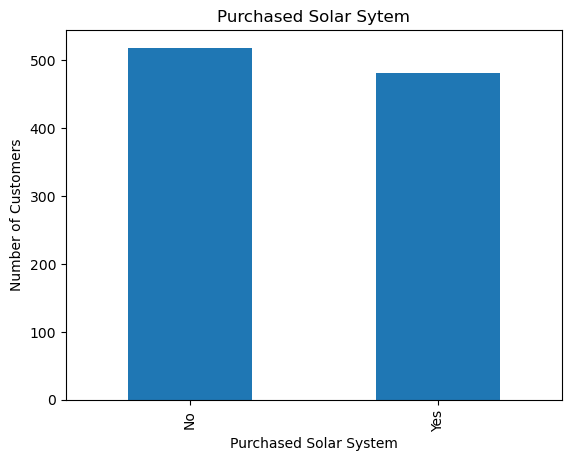

In [28]:
df["Purchased Solar System"].value_counts().plot(kind="bar")
plt.title("Purchased Solar Sytem")
plt.ylabel("Number of Customers")
plt.show()

more than half of the customers did not purchase a solar system

In [19]:
df.groupby("Age Group")["Purchase Flag"].mean() * 100

Age Group
30-39       59.468439
40-49       45.886076
50-59       45.945946
60+         32.173913
Under 30    42.168675
Name: Purchase Flag, dtype: float64

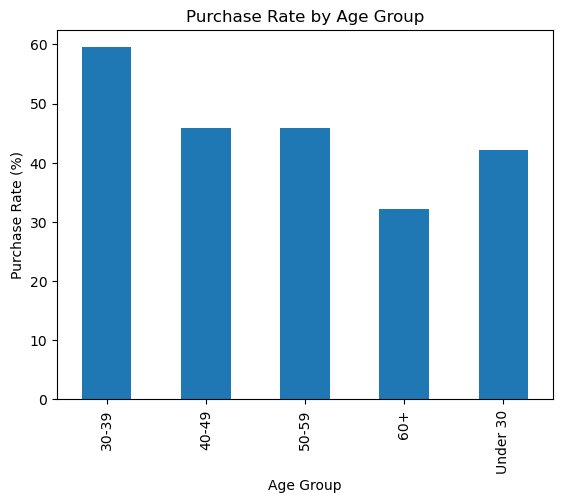

In [31]:
age_rate= df.groupby("Age Group")["Purchase Flag"].mean()* 100

age_rate.plot(kind="bar")
plt.title("Purchase Rate by Age Group")
plt.ylabel("Purchase Rate (%)")
plt.show()
              

customers aged 30-39 are the strongest purchasing group. 

In [20]:
df.groupby("Income Band")["Purchase Flag"].mean()*100

Income Band
100k+      48.571429
30k-49k    49.826990
50k-69k    49.268293
70k-99k    49.606299
<30k       40.136054
Name: Purchase Flag, dtype: float64

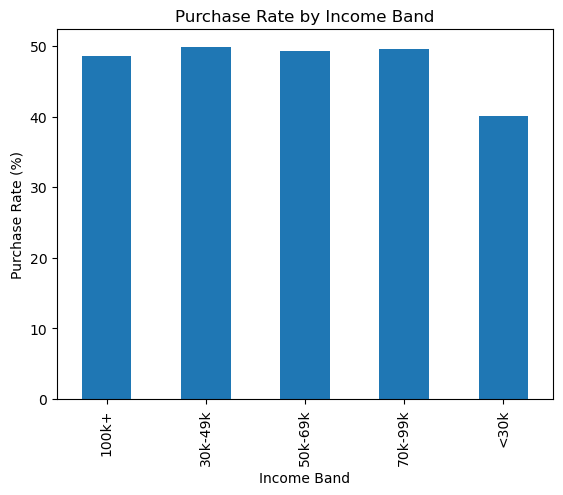

In [32]:
income_rate=df.groupby("Income Band")["Purchase Flag"].mean() *100

income_rate.plot(kind="bar")
plt.title("Purchase Rate by Income Band")
plt.ylabel("Purchase Rate (%)")
plt.show()

customers earning below 30k are less likely to purchase. SunVolt could offer financing options to the lower income customers, the highest income group does not even have the highest purchase rate and this shows there are other factors affecting customer purchasing beahavior.

In [21]:
df.groupby("Gender")["Purchase Flag"].mean()*100

Gender
Female    48.875256
Male      47.358121
Name: Purchase Flag, dtype: float64

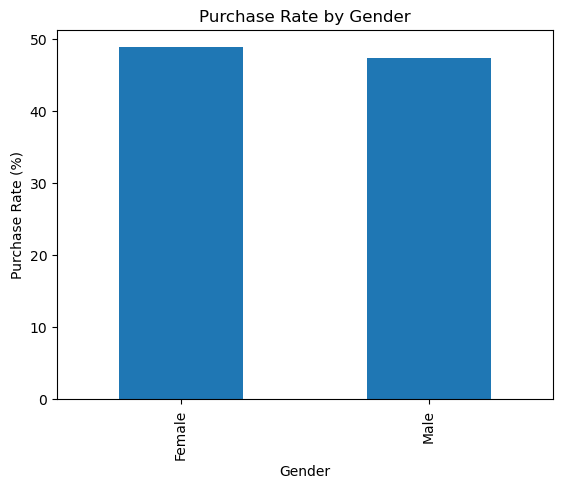

In [34]:
gender_rate=df.groupby("Gender")["Purchase Flag"].mean() *100

gender_rate.plot(kind="bar")
plt.title("Purchase Rate by Gender")
plt.ylabel("Purchase Rate (%)")
plt.show()

purchase rates are very similar across the two gender groups. Sunvolt should consider marketing to both groups rather than focusing heavily on one gender.

CUSTOMERS WHO DID NOT PURCHASE.

In [26]:
non_purchasers=df[df["Purchase Flag"]==0]
print(non_purchasers["Age Group"].value_counts())
print(non_purchasers.groupby("Income Band").size())
print(non_purchases.groupby("Gender").size())
print(non_purchasers.groupby("Region").size())

Age Group
40-49       171
30-39       122
50-59       100
60+          78
Under 30     48
Name: count, dtype: int64
Income Band
100k+       54
30k-49k    145
50k-69k    104
70k-99k    128
<30k        88
dtype: int64
Gender
Female    250
Male      269
dtype: int64
Region
Europe           152
North America    288
Pacific           79
dtype: int64


ii. GEOGRAPHICAL

calculation for purchase rate by region (percentage of customers) and total number of customers in each region

In [38]:
print(
    df.groupby("Region")["Purchase Flag"]
    .mean().mul(100).round(2)
)

print(df["Region"].value_counts())
    

Region
Europe           49.33
North America    43.31
Pacific          58.85
Name: Purchase Flag, dtype: float64
Region
North America    508
Europe           300
Pacific          192
Name: count, dtype: int64


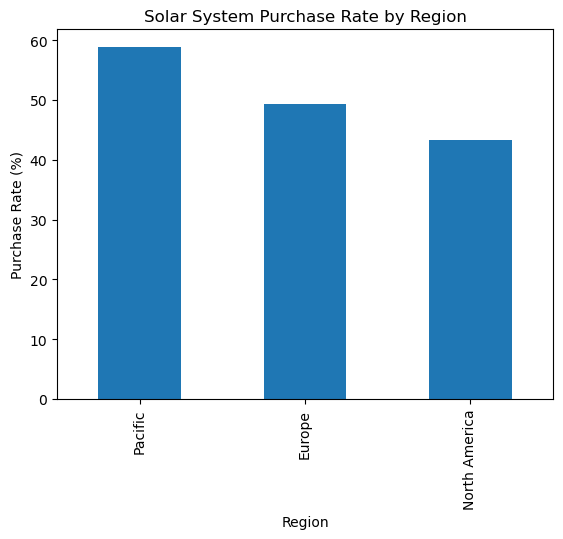

In [39]:
regional_rates = df.groupby("Region")["Purchase Flag"].mean() *100
regional_rates= regional_rates.sort_values(ascending=False)

regional_rates.plot(kind="bar")
plt.title("Solar System Purchase Rate by Region")
plt.ylabel("Purchase Rate (%)")
plt.show()
        

Region with highest purchase rate is Pacific at 58.85%
Middle perfoming region is Europe at 49.33%
Lowest purchase rate is North America at 43.31%

North America has the largest customer base with a total of 508 customers but it also records the highest number of non-purchasers at 288.
Europe had 300 customers which included 152 non purchasers.
Pacific region had 192 customers inclding 79 non-purchasers.

SunVolt Energy should investigate what could be detering customers from purchasing in North America


iii PURCHASE INFLUENCES

In [41]:
print(df.groupby("Marital Status")["Purchase Flag"].mean() *100)
print(df.groupby("Household Dependents")["Purchase Flag"].mean()*100)
print(df.groupby("Homeowner Status")["Purchase Flag"].mean()*100)
    
      

Marital Status
Married    42.936803
Single     54.112554
Name: Purchase Flag, dtype: float64
Household Dependents
0    50.533808
1    57.396450
2    46.411483
3    54.477612
4    42.857143
5    22.222222
Name: Purchase Flag, dtype: float64
Homeowner Status
No     49.211356
Yes    47.584187
Name: Purchase Flag, dtype: float64


Single customers have a higher purchase rate of 54.11& compared with 42,94% for married customers.

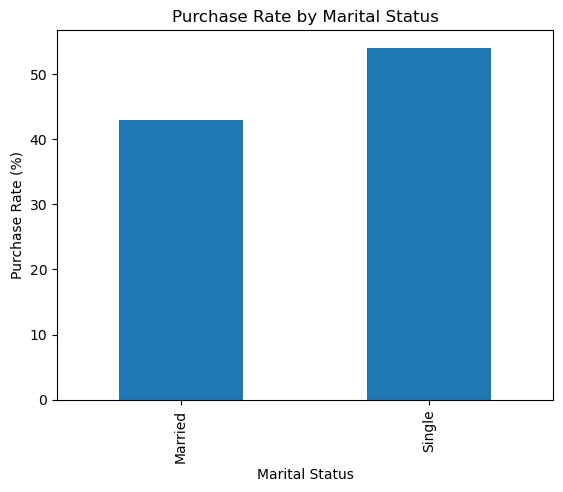

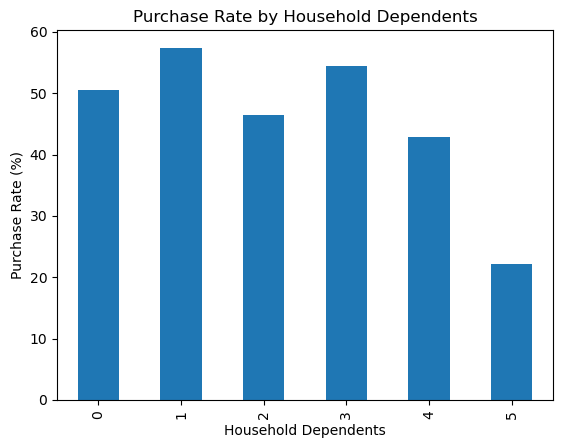

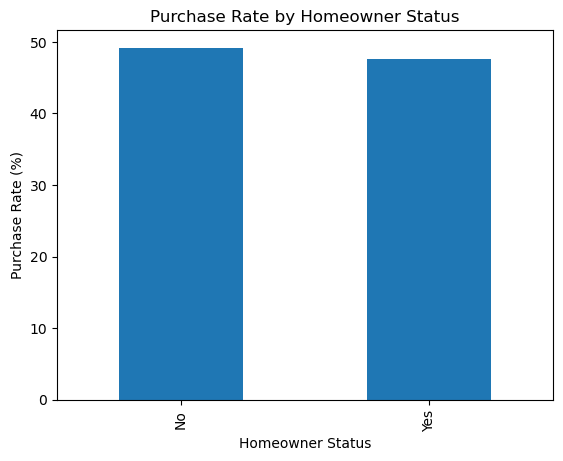

In [47]:
df.groupby("Marital Status")["Purchase Flag"].mean().mul(100).plot(kind="bar")
plt.title("Purchase Rate by Marital Status")
plt.ylabel("Purchase Rate (%)")
plt.show()

df.groupby("Household Dependents")["Purchase Flag"].mean().mul(100).plot(kind="bar")
plt.title("Purchase Rate by Household Dependents")
plt.ylabel("Purchase Rate (%)")
plt.show()

df.groupby("Homeowner Status")["Purchase Flag"].mean().mul(100).plot(kind="bar")
plt.title("Purchase Rate by Homeowner Status")
plt.ylabel("Purchase Rate (%)")
plt.show()

In [43]:
distance_analysis = df.groupby(
    ["Installer Distance Order", "Distance from Nearest Installer"]
).agg(
    Customers=("Purchase Flag", "size"),
    Purchases=("Purchase Flag", "sum"),
    Purchase_Rate=("Purchase Flag", "mean")
).reset_index()

distance_analysis["Purchase_Rate"]=(
    distance_analysis["Purchase_Rate"]*100
).round(2)

print(distance_analysis.sort_values("Installer Distance Order"))
    

   Installer Distance Order Distance from Nearest Installer  Customers  \
0                         1                          0-1 km        366   
1                         2                          1-2 km        169   
2                         3                          2-5 km        162   
3                         4                         5-10 km        192   
4                         5                          10+ km        111   

   Purchases  Purchase_Rate  
0        200          54.64  
1         77          45.56  
2         95          58.64  
3         76          39.58  
4         33          29.73  


Customers living 10+ km from an installer have the lowest purchase rate while customers 2-5km away have the highest.

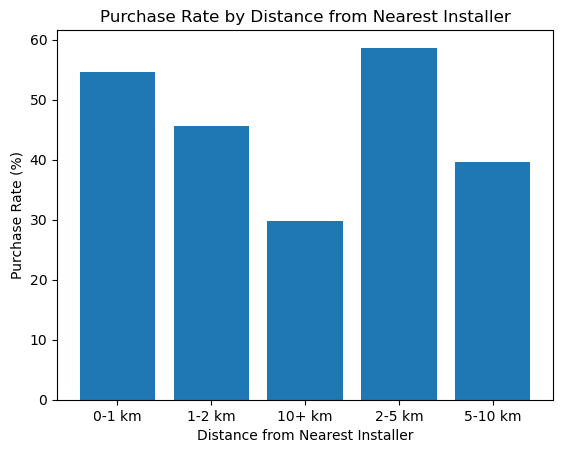

In [45]:
rates=df.groupby("Distance from Nearest Installer")["Purchase Flag"].mean()*100

plt.bar(rates.index, rates)
plt.title("Purchase Rate by Distance from Nearest Installer")
plt.xlabel("Distance from Nearest Installer")
plt.ylabel("Purchase Rate (%)")

plt.show()
    

In [ ]:
Customers who are close to installers install more because the service probably feels accessible
Marketing like door to door campaigns should be focused on the 0-5km customers,Virtual consultations can be used for customers who are 5-10km away 

QUESTION 2
saving cleaned dataset

In [48]:
df.to_csv("sunvolt_clean.csv",index=False)

In [51]:
import os

print(os.getcwd())
print(os.path.exists("sunvolt_clean.csv"))

C:\Users\macen
True


In [54]:
pip install dash pandas plotly openpyxl

Note: you may need to restart the kernel to use updated packages.


In [16]:
import pandas as pd
import os

print("Current folder:", os.getcwd())
print("CSV file found:", os.path.exists("sunvolt_clean.csv"))
      
df = pd.read_csv("sunvolt_clean.csv")
print("Dataset shape:", df.shape)
display(df.head())

Current folder: C:\Users\macen
CSV file found: True
Dataset shape: (1000, 17)


,Customer ID,Marital Status,Gender,Annual Income,Household Dependents,Education Level,Occupation,Homeowner Status,Vehicles Owned,Distance from Nearest Installer,Region,Age,Purchased Solar System,Purchase Flag,Age Group,Income Band,Installer Distance Order
0,12496,Married,Female,40000,1,Bachelors,Skilled Manual,Yes,0,0-1 km,Europe,42,No,0,40-49,30k-49k,1
1,24107,Married,Male,30000,3,Partial College,Clerical,Yes,1,0-1 km,Europe,43,No,0,40-49,30k-49k,1
2,14177,Married,Male,80000,5,Partial College,Professional,No,2,2-5 km,Europe,60,No,0,60+,70k-99k,3
3,24381,Single,Male,70000,0,Bachelors,Professional,Yes,1,5-10 km,Pacific,41,Yes,1,40-49,70k-99k,4
4,25597,Single,Male,30000,0,Bachelors,Clerical,No,0,0-1 km,Europe,36,Yes,1,30-39,30k-49k,1


In [40]:
!pip install plotly dash


In [41]:
import sys
print (sys.executable)

D:\AnacondaJupyter\python.exe


In [43]:
import os
os.chdir(r"C:\Users\macen\Sunvolt_Dashboard")
exec(open("app.py").read())
